# AURA | Mentor demonstration
**Susmit Naskar · CSE, Institute of Engineering and Management, Kolkata**  
Companion to manuscript V3.0: *Assessing the Limits of Disagreement-Aware Selective Prediction in an Axial Spondyloarthritis-Inspired Synthetic Benchmark*.

This notebook demonstrates actual model training and archived ten-seed evaluation. All records are generated by a simulator; no patient data or real MRI images are used. Outputs are illustrative scores, not medical predictions. The aim is to test whether disagreement improves selective prediction, not to diagnose disease.

## 1. Setup and inspect synthetic evidence
Run from the repository root. For Colab: upload/extract the repository ZIP, set the working directory to the extracted `AURA` folder, then install `requirements.txt`. All subsequent cells use local files. The pinned environment was tested on Python 3.13; Colab runtime versions may differ.

In [1]:
from pathlib import Path
import os
# Locate repository if opened in a nested directory.
if not Path('aura').is_dir() and Path('../aura').is_dir():
    os.chdir('..')
from aura.core import gen, acquire, names, rc, met, pred, cal, ef
from aura.demo import fit_demo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from io import BytesIO
def show_figure():
    buffer = BytesIO()
    plt.gcf().savefig(buffer, format='png', dpi=130, bbox_inches='tight')
    display(Image(data=buffer.getvalue()))
    plt.close()
pd.set_option('display.max_columns', 20)
results = Path('reference_results')
data = pd.read_csv('synthetic_seed0.csv')
print('Synthetic records:', len(data))
display(data.groupby('split').size().rename('records').to_frame())
display(data.head(3))

Synthetic records: 10000


,records
split,
calibration,1000
gate,1500
test,1500
train,5000
uncertainty,1000


,stiffness,movement_relief,night_pain,extra_articular,hla_b27,crp_z,esr_z,bme,erosion,structural_score,synthetic_label,latent_mimic_audit_only,split
0,1.0,1.0,1.0,1.0,1.0,0.081367,0.216927,1.0,1.0,-0.430736,1,0,train
1,1.0,1.0,1.0,0.0,0.0,1.169566,2.195552,1.0,1.0,1.303818,1,0,train
2,0.0,0.0,1.0,0.0,0.0,1.049014,-0.248269,1.0,0.0,-1.089882,0,1,train


## 2. Train a default AURA model live
The same seed and random draws as the manuscript's native AURA path are used. Three bootstrap logistic experts (five members per modality) produce scores and variances. The separate gate split learns expected squared error; inverse clipped error supplies reliability weights. A distinct calibration split fits a logistic recalibrator; another development split fits error rankers with and without disagreement.

In [2]:
model, x, mask, quality, y = fit_demo(seed=0)
print('Held-out complete synthetic observations:', len(y))
print('Development-selected cutoff:', round(model.threshold, 6))
print('Ensemble members by modality:', [len(e) for e in model.experts])
p, v = pred(model.experts, x, quality)
raw, w = model._fusion(p, mask, quality)
prob = cal(model.calibrator, raw)
base, full = ef(prob, raw, p, v, mask, quality, w)
u = model.full_ranker.predict_proba(full)[:,1]
observed = met(y, prob, u)
archived = pd.read_csv(results/'metrics.csv').query("seed == 0 and scenario == 'complete' and model == 'AURA' and ranking == 'native full'").iloc[0]
check = pd.DataFrame({'live': observed, 'archived': archived[list(observed)].astype(float)})
check['absolute_difference'] = (check.live-check.archived).abs()
assert np.allclose(check.live,check.archived,rtol=1e-8,atol=1e-9)
display(check.round(8))

Held-out complete synthetic observations: 1500
Development-selected cutoff: 0.375636
Ensemble members by modality: [5, 5, 5]


,live,archived,absolute_difference
auroc,0.880976,0.880976,0.0
auprc,0.832865,0.832865,0.0
brier,0.139113,0.139113,0.0
ece,0.043187,0.043187,0.0
logloss,0.432998,0.432998,0.0
accuracy,0.805333,0.805333,0.0
aurc,0.082630,0.082630,0.0
risk80,0.150000,0.150000,0.0
risk50,0.077333,0.077333,0.0
error_auc,0.748231,0.748231,0.0


## 3. Show missing-modality handling and attribution
A single held-out synthetic observation is evaluated with different masks. The benchmark forces at least one available modality; the demo adds an explicit no-evidence deferral guard. A change in score when evidence disappears is not a clinical interpretation. The attribution baseline is the calibrated score for raw probability 0.5, not population prevalence.

,synthetic_score,error_rank_score,disagreement_4D,decision
All available,0.3964,0.3478,0.1274,illustrative class 0
No laboratory,0.4897,0.4801,0.1604,defer
Clinical only,0.8207,0.1907,0.0000,illustrative class 1
None available,NaN,NaN,NaN,defer: no evidence


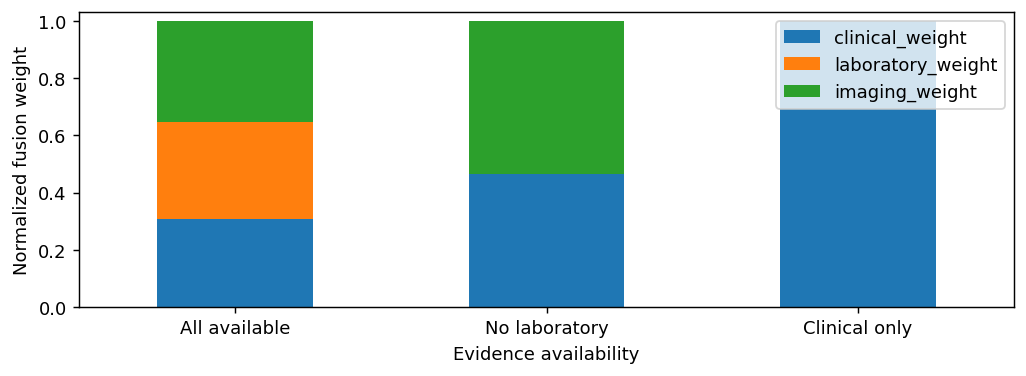

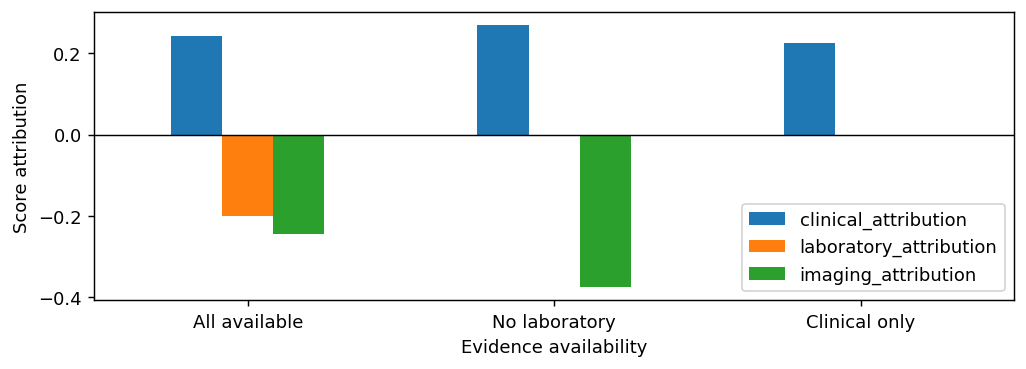

In [3]:
masks = np.array([[1,1,1],[1,0,1],[1,0,0],[0,0,0]])
demo = model.predict(np.repeat(x[:1],4,axis=0), masks, np.repeat(quality[:1],4,axis=0))
demo.index = ['All available','No laboratory','Clinical only','None available']
display(demo[['synthetic_score','error_rank_score','disagreement_4D','decision']].round(4))
ax=demo.iloc[:3][['clinical_weight','laboratory_weight','imaging_weight']].plot.bar(stacked=True,figsize=(8,3))
ax.set(ylabel='Normalized fusion weight', xlabel='Evidence availability', ylim=(0,1.03)); plt.xticks(rotation=0); plt.tight_layout(); show_figure()
ax=demo.iloc[:3][['clinical_attribution','laboratory_attribution','imaging_attribution']].plot.bar(figsize=(8,3))
ax.axhline(0,color='black',lw=.8); ax.set(ylabel='Score attribution',xlabel='Evidence availability'); plt.xticks(rotation=0); plt.tight_layout(); show_figure()

## 4. Compare classifiers fairly
Use the matched full error ranker for every classifier. Probability metrics are identical across rankers for each classifier; AURC measures selective risk. Lower Brier and AURC are better. These are macro means over ten seeds and seven conditions.

In [4]:
metrics = pd.read_csv(results/'metrics.csv')
assert len(metrics)==1400
matched = metrics.query("ranking == 'matched full'").groupby('model')[['auroc','auprc','brier','ece','aurc']].mean().sort_values('aurc')
display(matched.round(5))
comparison=metrics[metrics.ranking.isin(['entropy','matched no D','matched full'])].groupby(['model','ranking']).aurc.mean().unstack()
display(comparison.round(5))

,auroc,auprc,brier,ece,aurc
model,,,,,
Early logistic,0.82960,0.73295,0.15938,0.06309,0.11998
AURA,0.82706,0.71923,0.16136,0.06482,0.12191
Equal fusion,0.82455,0.71437,0.16286,0.06874,0.12353
Quality fusion,0.82487,0.71501,0.16280,0.06833,0.12367
Early HGB,0.81843,0.71505,0.16449,0.06400,0.12929
Early RF,0.81851,0.71543,0.16554,0.06939,0.13114


ranking,entropy,matched full,matched no D
model,,,
AURA,0.12598,0.12191,0.12196
Early HGB,0.12947,0.12929,0.12965
Early RF,0.13057,0.13114,0.13195
Early logistic,0.11934,0.11998,0.11972
Equal fusion,0.12808,0.12353,0.12325
Quality fusion,0.12802,0.12367,0.12315


## 5. Robustness, selective risk, and uncertainty
The curves summarize the actual saved evaluations. Bands are seed-level 95% t intervals across scenario-averaged curves. They are not patient-level confidence intervals.

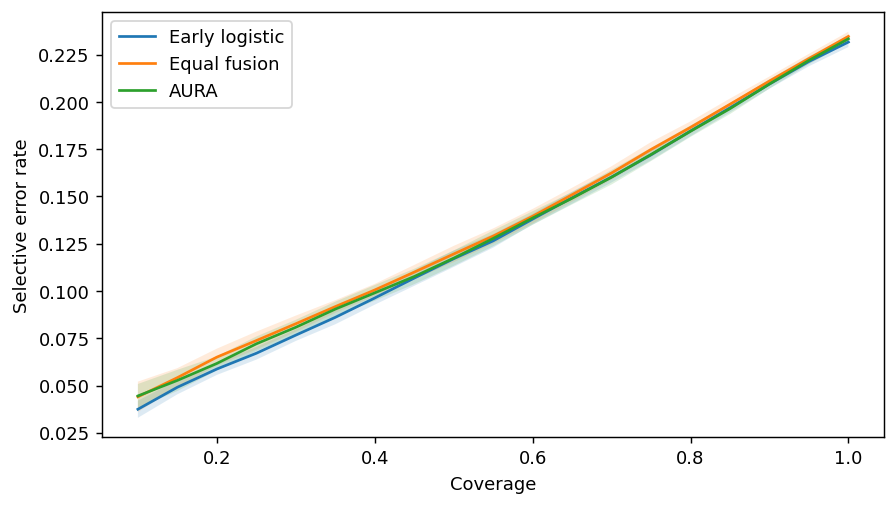

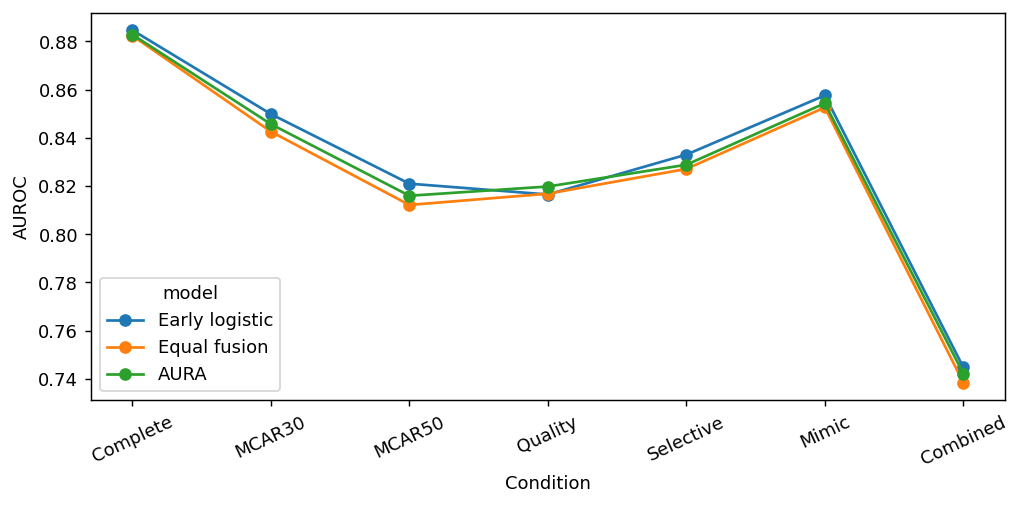

In [5]:
from scipy.stats import t
curves=pd.read_csv(results/'curves.csv')
fig,ax=plt.subplots(figsize=(7,4))
for name in ['Early logistic','Equal fusion','AURA']:
    z=curves[curves.model==name].groupby(['seed','coverage']).risk.mean().unstack()
    mu=z.mean(); h=t.ppf(.975,9)*z.std(ddof=1)/np.sqrt(10)
    ax.plot(mu.index,mu,label=name);ax.fill_between(mu.index,mu-h,mu+h,alpha=.15)
ax.set(xlabel='Coverage',ylabel='Selective error rate');ax.legend();plt.tight_layout();show_figure()
order=['complete','mcar30','mcar50','quality_shift','selective_acquisition','mimic_shift','combined_shift']
z=metrics.query("ranking == 'entropy'").groupby(['scenario','model']).auroc.mean().unstack().loc[order,['Early logistic','Equal fusion','AURA']]
ax=z.plot(marker='o',figsize=(8,4));ax.set(xlabel='Condition',ylabel='AUROC');plt.xticks(range(7),['Complete','MCAR30','MCAR50','Quality','Selective','Mimic','Combined'],rotation=25);plt.tight_layout();show_figure()

## 6. Primary negative result and sensitivity
The native AURA full and no-disagreement rankers share identical probabilities and classification labels. Their AURC difference isolates the effect of adding the disagreement feature in this implementation. A confidence interval crossing zero is not proof of equivalence.

,comparator,ranking,metric,delta,low,high
48,AURA,native full minus native no D,aurc,-0.000138,-0.000692,0.000415


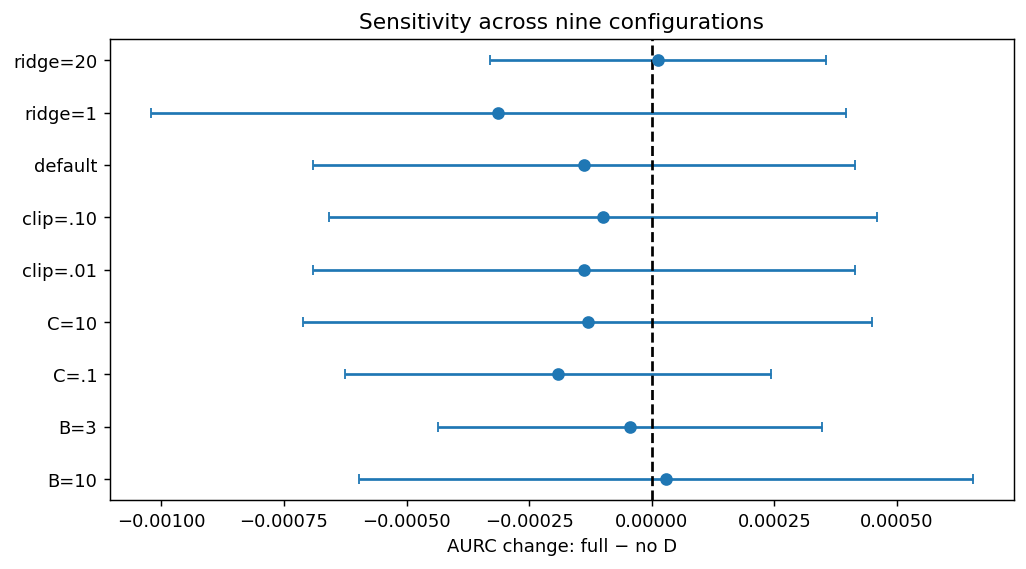

,coverage,risk
scenario,,
combined_shift,0.5956,0.2031
complete,0.8836,0.1608
mcar30,0.7697,0.1643
mcar50,0.7166,0.1791
mimic_shift,0.8744,0.1642
quality_shift,0.7001,0.1795
selective_acquisition,0.7661,0.1816


In [6]:
paired=pd.read_csv(results/'paired.csv')
display(paired.query("comparator == 'AURA' and ranking == 'native full minus native no D'").round(7))
sens=pd.read_csv(results/'sensitivity.csv').groupby(['variant','seed']).delta.mean().unstack()
mu=sens.mean(axis=1);h=t.ppf(.975,9)*sens.std(axis=1,ddof=1)/np.sqrt(10)
fig,ax=plt.subplots(figsize=(8,4.5));ax.errorbar(mu,range(len(mu)),xerr=h,fmt='o',capsize=3);ax.set_yticks(range(len(mu)),mu.index);ax.axvline(0,linestyle='--',color='black');ax.set(xlabel='AURC change: full − no D',title='Sensitivity across nine configurations');plt.tight_layout();show_figure()
thresholds=pd.read_csv(results/'thresholds.csv')
display(thresholds.groupby('scenario')[['coverage','risk']].mean().round(4))

## 7. What to tell the mentor
- Learned error ranking reduces AURC for AURA relative to entropy within the simulator.
- The added disagreement statistic does not show a statistically reliable improvement.
- Early logistic regression has the best average discrimination and remains a strong control.
- Clinical effectiveness, actual MRI analysis, fairness, external validation and patient-level conclusions are not established.

**Reproduce everything:** from the repository root run `python revision_experiment.py` and `python verify.py`. Run `python -m unittest discover -s tests -v` for implementation checks. The notebook itself does not replace the full benchmark.